In [1]:
from pylablib.devices import Thorlabs
import matplotlib.pyplot as plt
import os
import sys
import time
import socket
import threading
import csv
import numpy as np

from datetime import datetime
from ctypes import c_int16, c_int32, byref, c_char_p, c_float

from numpy.core.function_base import linspace
from picosdk.ps6000 import ps6000 as ps
from picosdk.functions import adc2mV, assert_pico_ok


# ---------------------------------------------------------------------
# Local component imports
# ---------------------------------------------------------------------

if socket.gethostname() == "ph-photonbec5":
    sys.path.append(r"D:/Control/PythonPackages/")

import Components as comp


# ---------------------------------------------------------------------
# Hardware setup
# ---------------------------------------------------------------------

laser = comp.Toptica_Laser()


powermeter = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0034379::INSTR',
    num_power_readings=15,
    bs_factor=1,
    wavelength=950
)

powermeter2 = comp.Thor_PowerMeter(
    power_meter_usb_name='USB0::0x1313::0x8078::P0046773::INSTR',
    num_power_readings=15,
    bs_factor=1,
    wavelength=950
)

from mdt69x import Controller
controller = Controller("COM4")

In [2]:
controller.set_x_voltage(25)

NameError: name 'controller' is not defined

In [63]:
laser.set(0.042)

24.6
24.6
24.7
24.8
24.8
24.9
25.0
25.0
25.1
25.1
25.2
25.2
25.3
25.4
25.4
25.5
25.6
25.6
25.7
25.7
25.8
25.9
25.9
26.0
26.0
26.1
26.2
26.2
26.3
26.3
26.4
26.5
26.5
26.6
26.6
26.7
26.8
26.8
26.9
27.0
27.0
27.1
27.1
27.2
27.2
27.3
27.4
27.4
27.5
27.5
27.6
27.7
27.7
27.8
27.9
27.9
28.0
28.0
28.1
28.2
28.2
28.3
28.3
28.4
28.5
28.5
28.6
28.6
28.7
28.8
28.8
28.9
28.9
29.0
29.1
29.1
29.2
29.2
29.3
29.4
29.4
29.5
29.5
29.6
29.7
29.7
29.8
29.9
29.9
30.0
30.0
30.1
30.2
30.2
30.3
30.3
30.4
30.5
30.5
30.6
[0.03582953067999999, 0.06177109743513333, 0.04006030776466667, 0.05397747365333332, 0.03404810826133333, 0.05787428627466666, 0.055981583133333346, 0.03939224970066667, 0.045070548435999995, 0.03260071296846666, 0.05442297259333334, 0.050303476233333325, 0.04150776592266667, 0.036720273957333335, 0.06511132151333335, 0.027145164448666666, 0.05687226270533334, 0.050526161221333334, 0.05186214949733334, 0.06232787514666666, 0.053532103026666666, 0.04373456103066667, 0.07958513894066667, 0.0363861

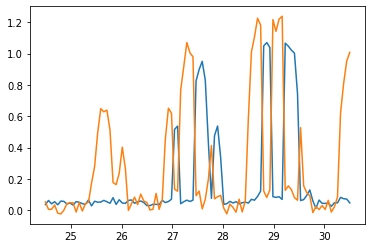

In [60]:
voltages = np.linspace(24.5,30.5,100)
poweroutx = []
powerouty = []
laser.set(0.027)


for x in voltages:
    power_reading = []
    power_reading_y = []
    controller.set_x_voltage(x)
    time.sleep(0.1)
    print(controller.get_x_voltage())
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        poweroutx.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
        powerouty.append(np.mean(np.array(power_reading_y)))

laser.set(0)
print(poweroutx)
print(powerouty)
print(voltages)
plt.plot(voltages,poweroutx)
plt.plot(voltages,powerouty)

29.1
29.1
29.1
29.1
29.2
29.2
29.2
29.2
29.2
29.3
29.3
29.3
29.3
29.3
29.4
29.4
29.4
29.4
29.4
29.5
29.5
29.5
29.5
29.5
29.5
29.6
29.6
29.6
29.6
29.7
29.7
29.7
29.7
29.7
29.8
29.8
29.8
29.8
29.9
29.9
29.9
29.9
29.9
30.0
30.0
30.0
30.0
30.0
30.1
30.1
[0.04974656966, 0.022803045112466665, 0.033157428142466666, 0.05052603354, 0.013784776066, 0.0314872833418, -0.0022479052781999988, 0.03638624553066667, -0.006812838972666666, 0.014452643058466667, 0.028592558686466662, 0.03137594092846666, 0.02859249437666667, 0.005211753627999996, 0.025809048894, 0.0218008938818, 0.030707946640000004, 0.05664957768846667, 0.018015361426666664, 0.028481215483799994, 0.03516153748666666, 0.02502977592, 0.015231979512466666, 0.030819353534666673, 0.03649739717733333, 0.04206454454266667, 0.01723615277513333, 0.05475687462913334, 0.034604886117333325, 0.04217576003266666, 0.034382136392666664, 0.04718587349066667, 0.023025666457333335, 0.004321072768, 0.028926587001333336, 0.01701353054466667, 0.043845904328,

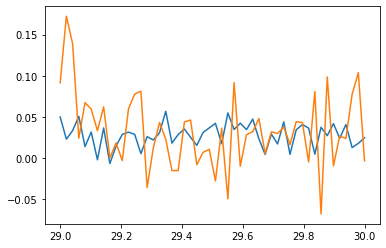

In [7]:
voltages = np.linspace(29,30,50)
poweroutx = []
powerouty = []
laser.set(0)


for x in voltages:
    power_reading = []
    power_reading_y = []
    controller.set_x_voltage(x)
    time.sleep(0.1)
    print(controller.get_x_voltage())
    for k in range(1):
        power_reading.append(10**6*powermeter.take_power_reading())
        poweroutx.append(np.mean(np.array(power_reading)))
        power_reading_y.append(10**6*powermeter2.take_power_reading())
        powerouty.append(np.mean(np.array(power_reading_y)))

laser.set(0)
print(poweroutx)
print(powerouty)
print(voltages)
plt.plot(voltages,poweroutx)
plt.plot(voltages,powerouty)

In [ ]:
# Scan settings 2D scan
# change power . scan voltage

voltages = np.linspace(23, 29, 300)
laser_values = np.linspace(0.040, 0.048, 9)

poweroutx = []
powerouty = []

for laser_power in laser_values:

    print(f"\nLaser = {laser_power:.5f}")
    laser.set(laser_power)
    time.sleep(0.5)

    power_scan_x = []
    power_scan_y = []

    for v in voltages:

        controller.set_x_voltage(v)
        time.sleep(0.1)

        print(controller.get_x_voltage())

        power_x = 1e6 * powermeter.take_power_reading()
        power_y = 1e6 * powermeter2.take_power_reading()

        power_scan_x.append(power_x)
        power_scan_y.append(power_y)

    poweroutx.append(power_scan_x)
    powerouty.append(power_scan_y)

laser.set(0)

print("\n========== Voltage ==========")
print(voltages)

print("\n========== Laser values ==========")
print(laser_values)

print("\n========== Power meter 1 ==========")
print(poweroutx)

print("\n========== Power meter 2 ==========")
print(powerouty)

In [2]:
from bidirectional_polarization_scan import run_bidirectional_scan

In [3]:
csv_path, metadata_path = run_bidirectional_scan(
    laser=laser,
    controller=controller,
    powermeter=powermeter,
    powermeter2=powermeter2,
)

print(csv_path)
print(metadata_path)

Block 1/2, pump=0.04100
Block 1/2, pump=0.05100
Block 1/2, pump=0.03700
Block 1/2, pump=0.04500
Block 1/2, pump=0.04900
Block 1/2, pump=0.05300
Block 1/2, pump=0.03100
Block 1/2, pump=0.06000
Block 1/2, pump=0.04500 (anchor)
Block 1/2, pump=0.05700
Block 1/2, pump=0.04300
Block 1/2, pump=0.04700
Block 1/2, pump=0.03300
Block 1/2, pump=0.04500 (anchor)
Block 1/2, pump=0.03900
Block 1/2, pump=0.05500
Block 1/2, pump=0.03500
Block 2/2, pump=0.03900
Block 2/2, pump=0.06000
Block 2/2, pump=0.04700
Block 2/2, pump=0.04300
Block 2/2, pump=0.04500 (anchor)
Block 2/2, pump=0.05500
Block 2/2, pump=0.05300
Block 2/2, pump=0.04900
Block 2/2, pump=0.03100
Block 2/2, pump=0.04500 (anchor)
Block 2/2, pump=0.04500
Block 2/2, pump=0.05700
Block 2/2, pump=0.05100
Block 2/2, pump=0.03300
Block 2/2, pump=0.04500 (anchor)
Block 2/2, pump=0.03700
Block 2/2, pump=0.04100


KeyboardInterrupt: 

In [4]:
from scan_speed_direction_test import run_scan_speed_direction_test

csv_path, metadata_path = run_scan_speed_direction_test(
    laser=laser,
    controller=controller,
    powermeter=powermeter,
    powermeter2=powermeter2,
)

print(csv_path)
print(metadata_path)

Planned: 18 bidirectional acquisitions, 36 individual scans
Estimated duration using 1.15 s meter overhead: 4.09 h
Block 1/3, condition 1/6, settle=0.000 s, order=increasing→decreasing
Block 1/3, condition 2/6, settle=2.000 s, order=decreasing→increasing
Block 1/3, condition 3/6, settle=0.500 s, order=increasing→decreasing
Block 1/3, condition 4/6, settle=0.500 s, order=decreasing→increasing
Block 1/3, condition 5/6, settle=2.000 s, order=increasing→decreasing
Block 1/3, condition 6/6, settle=0.000 s, order=decreasing→increasing
Block 2/3, condition 1/6, settle=0.500 s, order=decreasing→increasing
Block 2/3, condition 2/6, settle=2.000 s, order=increasing→decreasing
Block 2/3, condition 3/6, settle=0.000 s, order=decreasing→increasing
Block 2/3, condition 4/6, settle=0.500 s, order=increasing→decreasing
Block 2/3, condition 5/6, settle=2.000 s, order=decreasing→increasing
Block 2/3, condition 6/6, settle=0.000 s, order=increasing→decreasing
Block 3/3, condition 1/6, settle=0.500 s, ord